# Faults, repairs and replay

**A forecast can have the right numbers and still be wrong.** Shift it by one step and every value lands on the wrong date. Forget to undo a scaling step and every value comes back in the wrong units. A loss score calls both "a bit worse". TimeGym calls them broken.

In this notebook we take a forecast that is right, break it in several ways and see what TimeGym says each time. Then we repair one bug properly and replay the saved evidence, the way you would months later when someone asks "can you reproduce that?".

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from timegym import Forecast, GaussianAR1Forecaster, Pipeline, Scenario, TestReport
from timegym.checks import check_shift_equivariance
from timegym.diagnostics import evaluate_forecast
from timegym.mutations import mutate_forecast

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'pyproject.toml').is_file() and (p / 'timegym').is_dir())
plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})
pd.set_option('display.max_colwidth', None)


def checks_table(result):
    # One row per check TimeGym ran on a forecast.
    return pd.DataFrame([{'check': d.name, 'status': d.status, 'what it says': d.message}
                         for d in result.diagnostics])

## Start with a forecast that is right

The series is noise around a constant level of 50. Because we generated it, TimeGym holds the **answer key**: the true distribution of the next 12 values. We ask the answer key itself for a forecast, so we start from a forecast that cannot be wrong, and then break it on purpose.

Each row below is one check. The output checks (`forecast_contract`) PASS: right dates, right target, right shape, finite numbers, quantiles in order. The accuracy checks are **INCONCLUSIVE**: TimeGym scored them, but you haven't said how much error is too much, and it won't invent a pass mark for you.

In [2]:
scenario = Scenario('white_noise', context_length=120, horizon=12,
                    parameters={'mean': 50.0, 'sigma': 2.0})
case = scenario.generate(seed=7)
good_forecast = case.reference.forecast(n_samples=128, seed=19)
clean_result = evaluate_forecast(case, good_forecast)
display(checks_table(clean_result))

,check,status,what it says
0,forecast_contract,PASS,"Forecast indices, target order, shapes, finiteness, and quantile order satisfy the declared contract."
1,point_accuracy,INCONCLUSIVE,Point scores are descriptive; no capability acceptance tolerance was declared.
2,quantile_accuracy,INCONCLUSIVE,Quantile loss is descriptive; no capability acceptance tolerance was declared.
3,interval_coverage,INCONCLUSIVE,One-path coverage across possibly dependent coordinates does not establish calibration.
4,sample_scores,INCONCLUSIVE,Empirical marginal and joint scores are descriptive; no capability acceptance tolerance was declared.


## Bug 1: the right values on the wrong dates

The classic forecasting bug is an off-by-one: the model predicts the right values but labels them one step late. Here we take a forecast of a seasonal series and shift its labels by one. The values stay exactly the same.

A loss score would only report a somewhat larger error, because the values now trail the cycle by a step. TimeGym compares the dates you asked for with the dates you got back, and fails the forecast before scoring it.

In [3]:
seasonal_case = Scenario('seasonal', context_length=120, horizon=12,
                         parameters={'mean': 50.0, 'amplitude': 4.0, 'period': 12, 'sigma': 0.6}).generate(seed=7)
requested = seasonal_case.task.future_index
aligned = seasonal_case.reference.forecast(n_samples=128, seed=19)
shifted = mutate_forecast(aligned, 'index_shift')
shift_result = evaluate_forecast(seasonal_case, shifted)
index_check = next(d for d in shift_result.diagnostics if d.name == 'contract_index_mismatch')

np.testing.assert_array_equal(shifted.point, aligned.point)  # the same values...
assert index_check.status == 'FAIL'                           # ...on the wrong dates fail,
assert shift_result.metrics == {}                             # and a broken forecast gets no score.

print(f'{index_check.name}: {index_check.status}. {index_check.message}')
display(pd.DataFrame({'date asked for': requested, 'date returned': shifted.index,
                      'value': shifted.point[:, 0].round(2)}).head(4))

contract_index_mismatch: FAIL. Forecast index does not match the requested future index.


,date asked for,date returned,value
0,120,121,50.00
1,121,122,52.00
2,122,123,53.46
3,123,124,54.00


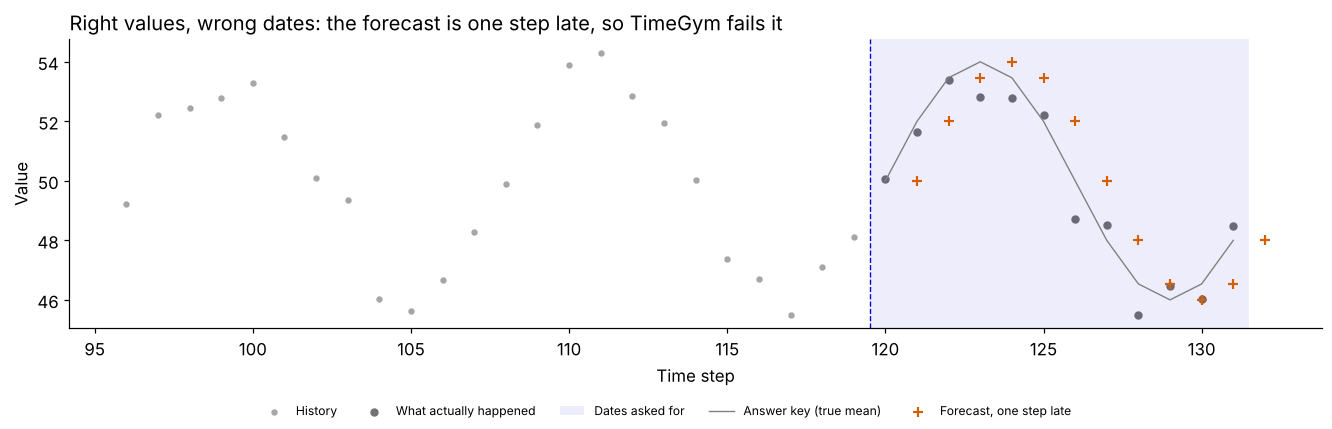

In [4]:
fig, ax = plt.subplots(figsize=(12, 3.8), layout='constrained')
history = seasonal_case.task.context.iloc[-24:, 0]
ax.scatter(history.index, history, color='0.65', s=10, label='History')
ax.scatter(seasonal_case.observed.index, seasonal_case.observed.iloc[:, 0], color='0.45', s=20,
           label='What actually happened')
ax.axvspan(requested[0] - 0.5, requested[-1] + 0.5, color='#0000CC', alpha=0.07, linewidth=0,
           label='Dates asked for')
ax.plot(seasonal_case.reference.index, seasonal_case.reference.mean[:, 0], color='0.5', linewidth=0.9,
        label='Answer key (true mean)')
ax.scatter(shifted.index, shifted.point[:, 0], marker='+', color='#D55E00', s=45, linewidths=1.4,
           label='Forecast, one step late')
ax.axvline(requested[0] - 0.5, color='#0000CC', linestyle='--', linewidth=0.9)
ax.set(title='Right values, wrong dates: the forecast is one step late, so TimeGym fails it',
       xlabel='Time step', ylabel='Value')
fig.legend(loc='outside lower center', ncol=5, fontsize=8)
fig.savefig(ROOT / 'docs' / 'images' / 'alignment-demo.png', dpi=110, bbox_inches='tight')
plt.show()

The orange crosses sit one step to the right of the shaded dates. Each one is the right value for the step before it. This figure is also the README's alignment preview.

## Bug 2: probabilities in the wrong order

A quantile forecast says "10% chance of being below this value, 50% below this one, 90% below that one". If the code that builds it reverses the order, the high value gets the low probability. Every number is still finite and every date is still right, so nothing crashes. TimeGym checks that the quantiles rise with their probability and fails this forecast, again before scoring it.

In [5]:
crossed = mutate_forecast(good_forecast, 'quantile_crossing')
crossed_result = evaluate_forecast(case, crossed)
crossing_check = next(d for d in crossed_result.diagnostics if d.name == 'contract_quantile_crossing')
assert crossing_check.status == 'FAIL' and crossed_result.metrics == {}
display(checks_table(crossed_result))

,check,status,what it says
0,contract_quantile_crossing,FAIL,Predicted quantiles decrease as the probability level increases.


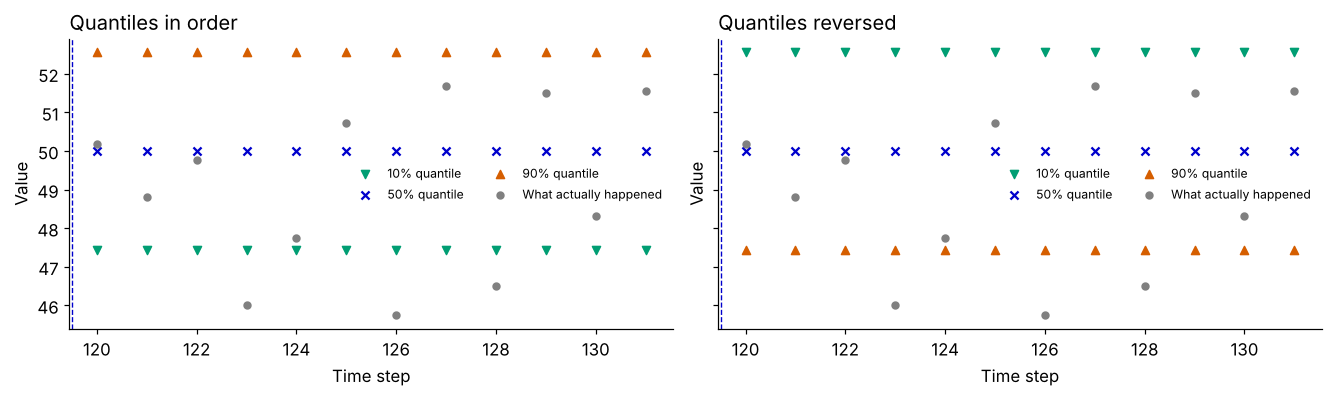

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True, layout='constrained')
quantile_styles = [('#009E73', 'v'), ('#0000CC', 'x'), ('#D55E00', '^')]
for ax, label, output in zip(axes, ['Quantiles in order', 'Quantiles reversed'],
                             [good_forecast, crossed]):
    for j, (level, (color, marker)) in enumerate(zip(output.levels, quantile_styles)):
        ax.scatter(output.index, output.quantiles[:, 0, j], marker=marker, s=28,
                   color=color, label=f'{level:.0%} quantile')
    ax.scatter(case.observed.index, case.observed.iloc[:, 0], s=20,
               color='0.5', label='What actually happened', zorder=5)
    ax.axvline(case.task.future_index[0] - 0.5, color='#0000CC', linestyle='--', linewidth=0.9)
    ax.set(title=label, xlabel='Time step', ylabel='Value')
    ax.legend(fontsize=8, ncol=2)
plt.show()

On the right, the green 10% marks sit on top and the orange 90% marks at the bottom.

## Not a bug: a forecast that is just bad

Now the opposite case. This forecast predicts zero for every step. It has the right dates, the right shape and no crossed quantiles, so it **passes** the output checks. It is simply a terrible forecast, and TimeGym reports it as one: a huge error, with point accuracy left INCONCLUSIVE until you say how much error is too much.

That is the line TimeGym draws: a broken forecast FAILs, a weak one gets a score. The quantile and sample checks are **UNSUPPORTED**: this forecast has no quantiles or samples, so there is nothing for them to check. TimeGym counts that as neither a pass nor a fail.

In [7]:
zeros = Forecast(index=case.task.future_index.copy(),
                 point=np.zeros((scenario.horizon, 1)),
                 target_names=case.task.target_names)
zeros_result = evaluate_forecast(case, zeros)
assert not any(d.status in {'FAIL', 'ERROR'} for d in zeros_result.diagnostics)  # weak, not broken
display(checks_table(zeros_result))
print(f"Mean squared error against what actually happened: {zeros_result.metrics['mse']:,.0f}")

,check,status,what it says
0,forecast_contract,PASS,"Forecast indices, target order, shapes, finiteness, and quantile order satisfy the declared contract."
1,point_accuracy,INCONCLUSIVE,Point scores are descriptive; no capability acceptance tolerance was declared.
2,quantile_accuracy,UNSUPPORTED,No explicit quantile forecasts were supplied.
3,sample_scores,UNSUPPORTED,No joint predictive samples were supplied.


Mean squared error against what actually happened: 2,410


The last kind of problem is a model that crashes. TimeGym records the case as **ERROR**, keeps the exception, and carries on with the other cases.

In [8]:
class CrashingModel:
    def fit(self, context):
        raise RuntimeError('a required fitted component is unavailable')


crash_report = Pipeline(CrashingModel).test([scenario], seeds=[7])
crash = crash_report.cases[0].diagnostics[0]
assert crash.status == 'ERROR'
print(f"{crash.status}: {crash.evidence['exception_type']}: {crash.evidence['exception_message']}")

ERROR: RuntimeError: a required fitted component is unavailable


## Bug 3: forgetting to undo the scaling

Many models standardize the data before fitting (subtract the mean, divide by the spread) and must undo that on the way out. Forget, and the forecast comes back in the wrong units: values near 0 when the series sits near 50.

The forecaster below predicts the historical mean, with that bug behind a switch. Both versions return the right dates and the right shape, so the output checks can't tell them apart. Their errors can.

In [9]:
class StandardizedMeanForecaster:
    def __init__(self, restore_units=True):
        self.restore_units = restore_units

    def clone_unfitted(self):
        return type(self)(restore_units=self.restore_units)

    def fit(self, context):
        values = context.to_numpy(dtype=float)
        self.location_ = values.mean(axis=0)
        raw_scale = values.std(axis=0)
        self.scale_ = np.where(raw_scale > 0, raw_scale, 1.0)
        standardized = (values - self.location_) / self.scale_
        self.standardized_mean_ = standardized.mean(axis=0)
        self.names_ = tuple(context.columns)
        return self

    def predict(self, future_index):
        prediction = self.standardized_mean_.copy()
        if self.restore_units:  # the repair: undo the standardization
            prediction = prediction * self.scale_ + self.location_
        return Forecast(index=future_index.copy(),
                        point=np.tile(prediction, (len(future_index), 1)),
                        target_names=self.names_)

In [10]:
broken_pipeline = Pipeline(StandardizedMeanForecaster(restore_units=False))
repaired_pipeline = Pipeline(StandardizedMeanForecaster(restore_units=True))
outputs = {name: pipeline.predict(case.task.context, case.task.future_index)
           for name, pipeline in [('Forgot to undo scaling', broken_pipeline),
                                  ('Units restored', repaired_pipeline)]}
repair_results = {name: evaluate_forecast(case, forecast) for name, forecast in outputs.items()}

# The repaired model predicts exactly the historical mean, as it should.
np.testing.assert_allclose(outputs['Units restored'].point[:, 0], case.task.context.mean().iloc[0])
display(pd.DataFrame({name: {'error against what happened (MSE)': result.metrics['mse'],
                             'error against the answer key (MSE)': result.metrics['mean_reference_mse'],
                             'output checks': next(d.status for d in result.diagnostics
                                                   if d.name == 'forecast_contract')}
                      for name, result in repair_results.items()}).T)

,error against what happened (MSE),error against the answer key (MSE),output checks
Forgot to undo scaling,2409.913807,2500.0,PASS
Units restored,4.848563,0.085763,PASS


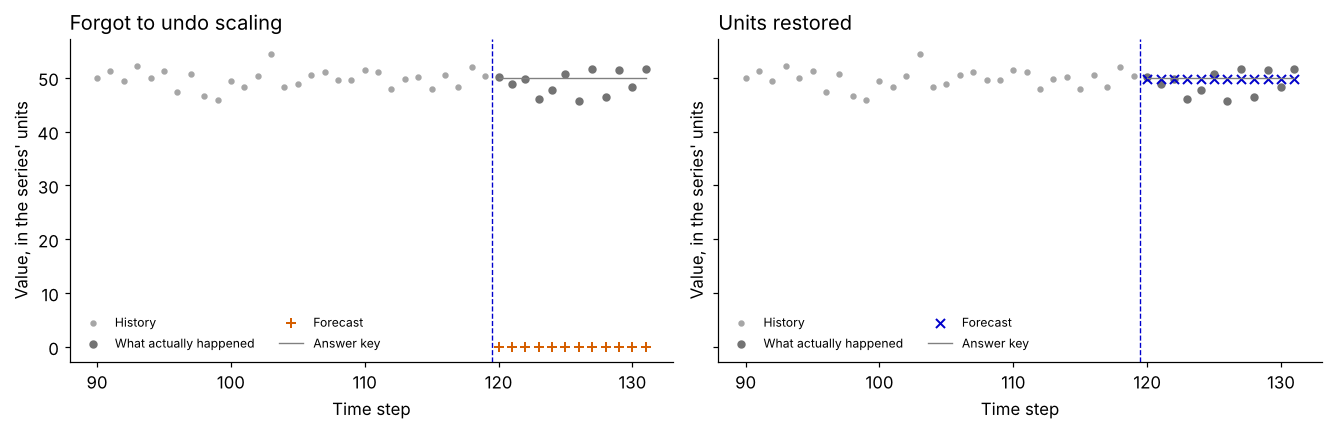

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True, layout='constrained')
for ax, (name, forecast) in zip(axes, outputs.items()):
    broken = name.startswith('Forgot')
    ax.scatter(case.task.context.index[-30:], case.task.context.iloc[-30:, 0],
               color='0.65', s=10, label='History')
    ax.scatter(case.observed.index, case.observed.iloc[:, 0], color='0.45', s=20,
               label='What actually happened')
    ax.scatter(forecast.index, forecast.point[:, 0], marker='+' if broken else 'x',
               color='#D55E00' if broken else '#0000CC', s=35, linewidths=1.3, label='Forecast')
    ax.plot(case.reference.index, case.reference.mean[:, 0], color='0.5', linewidth=0.9,
            label='Answer key')
    ax.axvline(case.task.future_index[0] - 0.5, color='#0000CC', linestyle='--', linewidth=0.9)
    ax.set(title=name, xlabel='Time step', ylabel='Value, in the series\' units')
    ax.legend(fontsize=8, ncol=2)
plt.show()

The broken forecast sits near zero while the series sits near 50. Both forecasts pass the same output checks.

## Is it a bug, or just a weak model?

A big error alone doesn't tell you. A model in the wrong units and a model that is merely poor can both score badly. What gives the bug away is a **promise the model breaks**.

This model predicts the historical mean, so it promises: *add 10 to every past value, and the forecast goes up by 10*. (The technical name is shift equivariance.) TimeGym can test that promise with `check_shift_equivariance`, without any answer key. The broken version fails: standardizing erases the shift, so its forecast doesn't move at all. The repaired version passes.

Only test promises your model actually makes. A model that clips its forecasts at zero, for example, rightly breaks this one.

In [12]:
shift_checks = {name: check_shift_equivariance(pipeline, case.task.context,
                                              case.task.future_index, shift=10.0)
                for name, pipeline in [('Forgot to undo scaling', broken_pipeline),
                                       ('Units restored', repaired_pipeline)]}
assert shift_checks['Forgot to undo scaling'].status == 'FAIL'
assert shift_checks['Units restored'].status == 'PASS'
display(pd.DataFrame([{'model': name, 'status': d.status, 'shift': d.evidence['shift'],
                       'how far the forecast missed the shift': d.evidence['max_absolute_error']}
                      for name, d in shift_checks.items()]))

,model,status,shift,how far the forecast missed the shift
0,Forgot to undo scaling,FAIL,10.0,10.0
1,Units restored,PASS,10.0,0.0


## Every case gets a fresh model

One more promise, this time from TimeGym itself: every forecast comes from a brand-new model, so nothing learned on one history leaks into the next. Pass a factory and you can watch it happen. Two forecasts, two models, each fitted only on its own history, and the second history is the first plus 10.

In [13]:
constructed = []


def model_factory():
    model = StandardizedMeanForecaster(restore_units=True)
    constructed.append(model)
    return model


factory_pipeline = Pipeline(model_factory=model_factory)
first = factory_pipeline.predict(case.task.context, case.task.future_index)
second = factory_pipeline.predict(case.task.context + 10.0, case.task.future_index)
assert len(constructed) == 2 and constructed[0] is not constructed[1]
np.testing.assert_allclose(second.point, first.point + 10.0)
display(pd.DataFrame({'forecast': [1, 2],
                      'mean the model learned': [model.location_[0] for model in constructed]}))

,forecast,mean the model learned
0,1,49.707147
1,2,59.707147


## Months later: replay the evidence

A failure you can't reproduce is a rumour. A TimeGym report saves what it takes to rerun each case: the scenario and its seed, the model settings, the library versions and a fingerprint of the source code. Here we save a report to a file, load it back and replay every case. The table confirms that the scores, the checks and the recorded settings come out the same.

In the same environment the replay matches exactly. On another machine or with other library versions small numerical differences are possible, and the replay table says which parts differ.

In [14]:
replay_scenario = Scenario('ar1', context_length=100, horizon=6,
                           parameters={'mean': 3.0, 'phi': 0.65, 'sigma': 0.7})
replay_pipeline = Pipeline(GaussianAR1Forecaster(n_samples=96, seed=23))
saved_report = replay_pipeline.test([replay_scenario], seeds=[7, 11], check_dependence=False)
with TemporaryDirectory(prefix='timegym-notebook-') as directory:
    report_path = Path(directory) / 'report.json'
    saved_report.to_json(report_path)
    loaded_report = TestReport.read(report_path)
    replayed = [loaded_report.replay_case(case_index=i) for i in range(len(saved_report.cases))]
comparisons = pd.DataFrame([r.metadata['replay'] for r in replayed])
assert comparisons['reproduced'].all()
display(comparisons[['case_index', 'metrics_match', 'diagnostics_match', 'manifest_match', 'reproduced']])
print('Saved model settings:', loaded_report.metadata['pipeline_config']['model'])

,case_index,metrics_match,diagnostics_match,manifest_match,reproduced
0,0,True,True,True,True
1,1,True,True,True,True


Saved model settings: {'class': 'GaussianAR1Forecaster', 'kind': 'builtin', 'parameters': {'levels': [0.1, 0.5, 0.9], 'n_samples': 96, 'seed': 23}}


## Your own models are not rebuilt from a file

Replay rebuilds TimeGym's built-in models from their saved settings. It will not rebuild your own class from a report file, because that would mean running code found in a file. For a model you wrote, keep the notebook or script that defines it, together with its settings and seeds. TimeGym says so instead of guessing:

In [15]:
custom_report = repaired_pipeline.test([scenario], seeds=[7])
assert custom_report.metadata['pipeline_config']['replayable'] is False
try:
    custom_report.replay_case()
except ValueError as exc:
    print(f'{type(exc).__name__}: {exc}')
else:
    raise AssertionError('Custom code must not become executable through report JSON.')

ValueError: This model configuration is not automatically replayable; supply its original model code


## The recipe

When a forecast looks wrong:

1. Keep the smallest case that shows it: one scenario, one seed.
2. Look at the output itself: dates, target order, units, quantile order.
3. Write down a promise the model makes, and test it.
4. Fix the code, then rerun the same case and compare.

**Try it.** Change the scenario's mean from 50 to 5,000. The broken forecast now misses by about 5,000 instead of 50, the output checks still pass, and the shift test still catches the bug.

**What this doesn't show.** A broken promise tells you that something is wrong, not exactly what. Statistical checks can occasionally reject a correct forecast at their stated error rate, which is why the replay example turns the covariance check off. `assert_passed()` rejects FAIL and ERROR only; it doesn't count scored or unchecked results as proof of skill.

**Next:** [Target transforms](04_target_transforms.ipynb).